# Product Title Clustering with TF-IDF, K-Means++ and DBSCAN

**Purpose:** Explore product-title data and compare text-based clustering approaches.

## Dataset schema expected
The dataset has seven columns, with some leading spaces in column names:

- `Product ID`
- `Product Title`
- `Merchant ID`
- `Cluster ID`
- `Cluster Label`
- `Category ID`
- `Category Label`

This notebook normalises column names by stripping whitespace. It uses **Product Title** as the main text input. `Product ID`, `Merchant ID`, existing `Cluster ID`, `Cluster Label`, `Category ID`, and `Category Label` are not used as model input. Existing cluster/category fields are reserved for later descriptive comparison only.

## Methods included
1. Text exploration and data quality checks
2. TF-IDF representation of product titles
3. K-Means with `init="k-means++"`
4. Elbow method to help choose K
5. DBSCAN on a reduced TF-IDF representation, because DBSCAN can be expensive in high-dimensional sparse text spaces
6. Evaluation and inspection of example titles per cluster

**Important:** Existing `Cluster ID` and `Cluster Label` appear to be reference/grouping labels. Do not feed them into clustering, because doing so would leak the answers into the features. The notebook does not assume a particular best number of clusters in advance.


## 1. Imports and configuration

If a package import fails, install it into the active notebook environment. This notebook does not automatically install packages each time it runs.

In [3]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42
DATA_PATH = "pricerunner_aggregate.csv"  # Change this to your actual CSV filename

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("Working directory:", os.getcwd())
print("Dataset path:", os.path.abspath(DATA_PATH))
print("Dataset exists:", os.path.exists(DATA_PATH))


Python: 3.12.15 (main, Sep 30 2026, 22:04:19) [Clang 21.0.0 (clang-2100.3.34.2)]
Python executable: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/Machine-Learning/projects/.venv/bin/python
Working directory: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/Machine-Learning/projects
Dataset path: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/Machine-Learning/projects/pricerunner_aggregate.csv
Dataset exists: True


## 2. Load data and fix column-name whitespace

Your printed schema contains names such as `' Merchant ID'`, `' Cluster ID'`, and `' Cluster Label'`. We remove leading/trailing whitespace from every column name so later code can refer to consistent names.

In [4]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH!r}. Set DATA_PATH to the location of your product dataset CSV."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = df.columns.astype(str).str.strip()

print("Shape:", df.shape)
print("Columns after stripping whitespace:")
print(df.columns.tolist())
display(df.head())

expected = [
    "Product ID", "Product Title", "Merchant ID",
    "Cluster ID", "Cluster Label", "Category ID", "Category Label"
]
missing_expected = [c for c in expected if c not in df.columns]
if missing_expected:
    print("Expected columns not found:", missing_expected)
    print("Please verify the source CSV and column names.")


Shape: (35311, 7)
Columns after stripping whitespace:
['Product ID', 'Product Title', 'Merchant ID', 'Cluster ID', 'Cluster Label', 'Category ID', 'Category Label']


,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphone in gold,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


## 3. Dataset structure and data quality

We check data types, missing values, duplicate rows, duplicate titles, and uniqueness. Duplicate product titles may be legitimate when multiple merchants sell the same item, so we report them rather than automatically deleting them.

In [5]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nData types:")
display(df.dtypes.astype(str).rename("dtype").to_frame())

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(3)
}).sort_values("missing_count", ascending=False)
display(missing_summary)

print("Exact duplicate rows:", int(df.duplicated().sum()))
if "Product Title" in df.columns:
    clean_titles_preview = df["Product Title"].astype("string").str.strip()
    print("Blank/missing titles:", int(clean_titles_preview.isna().sum() + clean_titles_preview.eq("").sum()))
    print("Unique non-empty titles:", clean_titles_preview[clean_titles_preview.notna() & clean_titles_preview.ne("")].nunique())
    print("Titles occurring more than once:", int(clean_titles_preview.value_counts().gt(1).sum()))


Rows: 35311
Columns: 7

Data types:


,dtype
Product ID,int64
Product Title,str
Merchant ID,int64
Cluster ID,int64
Cluster Label,str
Category ID,int64
Category Label,str


,missing_count,missing_percent
Product ID,0,0.0
Product Title,0,0.0
Merchant ID,0,0.0
Cluster ID,0,0.0
Cluster Label,0,0.0
Category ID,0,0.0
Category Label,0,0.0


Exact duplicate rows: 0
Blank/missing titles: 0
Unique non-empty titles: 30993
Titles occurring more than once: 3184


## 4. Understand existing reference labels

These columns may be useful for interpreting clusters after fitting, but they must not be part of the clustering input. `Cluster ID` and `Cluster Label` may represent existing group assignments, while `Category Label` describes a broader product category. We inspect their distributions only.

In [6]:
for col in ["Cluster ID", "Cluster Label", "Category ID", "Category Label", "Merchant ID"]:
    if col in df.columns:
        print(f"\n{col}: {df[col].nunique(dropna=False)} distinct values")
        display(df[col].value_counts(dropna=False).head(20).rename("count").to_frame())



Cluster ID: 13233 distinct values


,count
Cluster ID,
38848,27
4419,24
38849,24
1,23
4420,23
4425,23
38850,23
2,22
3,22



Cluster Label: 12849 distinct values


,count
Cluster Label,
Canon IXUS 185,27
Samsung UE49NU7100,24
Canon PowerShot SX730 HS,24
Apple iPhone 8 Plus 64GB,23
Samsung UE65NU7100,23
Samsung UE75NU7100,23
Canon IXUS 285 HS,23
Apple iPhone 7 Plus 32GB,22
Apple iPhone 7 32GB,22



Category ID: 10 distinct values


,count
Category ID,
2622,5501
2612,4081
2620,4044
2615,3862
2623,3584
2614,3564
2619,3424
2617,2697
2618,2342



Category Label: 10 distinct values


,count
Category Label,
Fridge Freezers,5501
Mobile Phones,4081
Washing Machines,4044
CPUs,3862
Fridges,3584
TVs,3564
Dishwashers,3424
Digital Cameras,2697
Microwaves,2342



Merchant ID: 306 distinct values


,count
Merchant ID,
3,2547
6,1591
298,1523
31,1350
119,1239
7,1204
17,1193
293,1177
294,1000


## 5. Clean product titles

The title is the main source of semantic information. We fill missing titles with empty strings, trim whitespace, and remove rows whose title is empty. We retain the original rows and create a working copy so results can later be joined back to the source data.

In [7]:
if "Product Title" not in df.columns:
    raise KeyError("Required column 'Product Title' is missing.")

work = df.copy()
work["Product Title"] = work["Product Title"].fillna("").astype(str).str.strip()
work = work.loc[work["Product Title"].ne("")].copy()
work = work.reset_index(drop=True)

print("Rows available for text clustering:", len(work))
display(work[["Product Title"]].head(10))


Rows available for text clustering: 35311


,Product Title
0,apple iphone 8 plus 64gb silver
1,apple iphone 8 plus 64 gb spacegrau
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphone in gold
3,apple iphone 8 plus 64gb space grey
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free
5,apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free
6,apple iphone 8 plus 64 gb space grey
7,apple iphone 8 plus 64gb space grey
8,apple iphone 8 plus 64gb space grey
9,apple iphone 8 plus 64gb space grey


## 6. Do we need TF-IDF?

**Yes, TF-IDF is a strong starting point for product-title clustering.** Product titles are short text strings containing brand, model, storage size, colour, and other attributes. TF-IDF converts titles into numeric vectors that reflect which words are informative within the dataset.

The vectorizer below uses word unigrams and bigrams. Bigrams can preserve phrases such as `iphone 8`, `64 gb`, and `space grey`. We use English stop words cautiously; product titles can contain meaningful short tokens, so inspect the resulting vocabulary and examples. TF-IDF is sparse and high-dimensional, which suits text but affects clustering choices.

In [8]:
tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    norm="l2",
    token_pattern=r"(?u)\b\w+\b"
)

X_tfidf = tfidf.fit_transform(work["Product Title"])

print("TF-IDF matrix shape (products, terms):", X_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Matrix density:", round(X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1]), 6))
print("Example vocabulary terms:", list(tfidf.vocabulary_.keys())[:40])


TF-IDF matrix shape (products, terms): (35311, 37178)
Vocabulary size: 37178
Matrix density: 0.000409
Example vocabulary terms: ['apple', 'iphone', '8', 'plus', '64gb', 'silver', 'apple iphone', 'iphone 8', '8 plus', 'plus 64gb', '64gb silver', '64', 'gb', 'spacegrau', 'plus 64', '64 gb', 'gb spacegrau', 'a', '5', '12mp', 'sim', 'free', 'smartphone', 'in', 'gold', 'a iphone', '64gb 5', '5 5', '5 12mp', '12mp sim', 'sim free', 'free smartphone', 'smartphone in', 'in gold', 'space', 'grey', '64gb space', 'space grey', '4g', 'unlocked']


## 7. Inspect important TF-IDF terms and title similarity

This cell shows terms with high aggregate TF-IDF weight and gives a simple similarity check for a few titles. Similarity is not a final quality score; it helps confirm whether the vector representation captures obvious title overlap.

In [9]:
terms = np.array(tfidf.get_feature_names_out())
mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_term_idx = np.argsort(mean_tfidf)[::-1][:30]

top_terms = pd.DataFrame({
    "term": terms[top_term_idx],
    "mean_tfidf": mean_tfidf[top_term_idx]
})
display(top_terms)

sample_n = min(8, len(work))
if sample_n >= 2:
    similarity = (X_tfidf[:sample_n] @ X_tfidf[:sample_n].T).toarray()
    similarity_df = pd.DataFrame(
        similarity,
        index=[f"{i}: {t[:35]}" for i, t in enumerate(work["Product Title"].iloc[:sample_n])],
        columns=[f"{i}: {t[:35]}" for i, t in enumerate(work["Product Title"].iloc[:sample_n])]
    )
    display(similarity_df.round(3))


,term,mean_tfidf
0,fridge,0.022602
1,freezer,0.022291
2,white,0.018233
3,fridge freezer,0.018078
4,bosch,0.015879
5,in,0.015778
6,free,0.013849
7,black,0.013446
8,a,0.012691
9,integrated,0.012280


,0: apple iphone 8 plus 64gb silver,1: apple iphone 8 plus 64 gb spacegrau,2: apple mq8n2b/a iphone 8 plus 64gb 5,3: apple iphone 8 plus 64gb space grey,4: apple iphone 8 plus gold 5.5 64gb 4,5: apple iphone 8 plus gold 5.5 64gb 4,6: apple iphone 8 plus 64 gb space gre,7: apple iphone 8 plus 64gb space grey
0: apple iphone 8 plus 64gb silver,1.000,0.466,0.448,0.710,0.456,0.456,0.452,0.710
1: apple iphone 8 plus 64 gb spacegrau,0.466,1.000,0.252,0.417,0.334,0.334,0.694,0.417
2: apple mq8n2b/a iphone 8 plus 64gb 5,0.448,0.252,1.000,0.401,0.415,0.415,0.245,0.401
3: apple iphone 8 plus 64gb space grey,0.710,0.417,0.401,1.000,0.407,0.407,0.612,1.000
4: apple iphone 8 plus gold 5.5 64gb 4,0.456,0.334,0.415,0.407,1.000,1.000,0.324,0.407
5: apple iphone 8 plus gold 5.5 64gb 4,0.456,0.334,0.415,0.407,1.000,1.000,0.324,0.407
6: apple iphone 8 plus 64 gb space gre,0.452,0.694,0.245,0.612,0.324,0.324,1.000,0.612
7: apple iphone 8 plus 64gb space grey,0.710,0.417,0.401,1.000,0.407,0.407,0.612,1.000


## 8. K-Means++ and the elbow method

Scikit-learn's `KMeans(init="k-means++")` uses K-Means++ to choose initial centroids. The elbow method plots within-cluster sum of squares (`inertia_`) against K. We choose a manageable K range and use a reproducible sample for silhouette scoring if the dataset is large.

The elbow is a heuristic, not a definitive answer. TF-IDF text clusters can have a gradual elbow, so consider silhouette scores and whether example titles within clusters are meaningful.

K= 2 | inertia=34715.357
K= 3 | inertia=34411.202
K= 4 | inertia=34174.580
K= 5 | inertia=34014.350
K= 6 | inertia=33786.178
K= 7 | inertia=33674.998
K= 8 | inertia=33512.972
K= 9 | inertia=33413.989
K=10 | inertia=33267.776
K=11 | inertia=33177.116
K=12 | inertia=33060.866
K=13 | inertia=32929.256
K=14 | inertia=32831.701
K=15 | inertia=32807.997


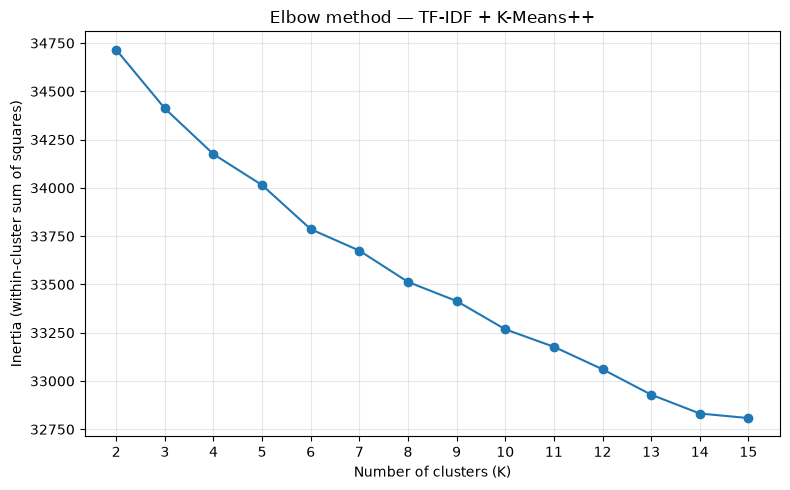

In [10]:
n_rows = X_tfidf.shape[0]
if n_rows < 3:
    raise ValueError("At least three non-empty product titles are needed for clustering.")

# Keep the range valid for the number of rows. Adjust max_k after inspecting dataset size.
max_k = min(15, n_rows - 1)
k_values = list(range(2, max_k + 1))
inertias = []
kmeans_models = {}

# Inertia uses all records; for very large datasets this may take time.
for k in k_values:
    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=RANDOM_STATE
    )
    km.fit(X_tfidf)
    inertias.append(km.inertia_)
    kmeans_models[k] = km
    print(f"K={k:2d} | inertia={km.inertia_:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow method — TF-IDF + K-Means++")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Compare candidate K values with silhouette score

Silhouette score measures how similar an item is to its own cluster compared with other clusters. Higher is generally better, but full silhouette calculation can be expensive. We use a reproducible sample and cosine distance, which is commonly useful for text vectors.

The score is a diagnostic alongside the elbow curve—not a substitute for inspecting cluster contents.

In [11]:
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(RANDOM_STATE)
silhouette_rows = []
sil_sample_size = min(5000, X_tfidf.shape[0])
sample_idx = rng.choice(X_tfidf.shape[0], size=sil_sample_size, replace=False)
X_sil = X_tfidf[sample_idx]

for k, model in kmeans_models.items():
    labels_all = model.labels_
    labels_sil = labels_all[sample_idx]
    if len(np.unique(labels_sil)) < 2 or len(np.unique(labels_sil)) >= len(labels_sil):
        score = np.nan
    else:
        score = silhouette_score(X_sil, labels_sil, metric="cosine")
    silhouette_rows.append({"K": k, "inertia": model.inertia_, "sample_silhouette_cosine": score})

silhouette_table = pd.DataFrame(silhouette_rows).sort_values("sample_silhouette_cosine", ascending=False)
display(silhouette_table.round(4))


,K,inertia,sample_silhouette_cosine
12,14,32831.7011,0.0489
13,15,32807.9971,0.0472
9,11,33177.1159,0.0426
11,13,32929.2560,0.0418
10,12,33060.8657,0.0414
8,10,33267.7756,0.0393
6,8,33512.9717,0.0375
7,9,33413.9887,0.0343
5,7,33674.9980,0.0342
4,6,33786.1778,0.0322


## 10. Select a K and inspect K-Means++ clusters

After reviewing the elbow and silhouette table, set `SELECTED_K` to the K you want to inspect. The default below chooses the best sampled silhouette score among the tested candidates, but you should confirm it against the elbow and the actual titles. Then the notebook prints representative titles closest to each centroid and adds the cluster assignment to a copy of the data.

In [12]:
valid_sil = silhouette_table.dropna(subset=["sample_silhouette_cosine"])
if len(valid_sil):
    suggested_k = int(valid_sil.iloc[0]["K"])
else:
    suggested_k = int(k_values[0])

SELECTED_K = suggested_k  # Change after reviewing elbow + silhouette results
print("Suggested K from sampled silhouette:", suggested_k)
print("K used for inspection:", SELECTED_K)

kmeans_final = kmeans_models[SELECTED_K]
work["KMeans Cluster"] = kmeans_final.labels_

def show_cluster_titles(frame, cluster_col, n_examples=10):
    for cluster_id in sorted(frame[cluster_col].unique()):
        subset = frame.loc[frame[cluster_col] == cluster_id, "Product Title"]
        print(f"\nCluster {cluster_id} — {len(subset)} products")
        for title in subset.head(n_examples):
            print(" •", title)

show_cluster_titles(work, "KMeans Cluster", n_examples=10)


Suggested K from sampled silhouette: 14
K used for inspection: 14

Cluster 0 — 1722 products
 • bosch hmt72m450b silver freestanding microwave oven
 • bosch hmt72m450b 17 litre microwave with grill brushed steel
 • bosch hmt72m450b 800w microwave oven with 5 power levels
 • bosch free standing microwave oven in brushed steel
 • bosch hmt72m450b compact microwave oven in stainless steel 800w 17l
 • bosch hmt72m450b freestanding microwave
 • bosch hmt72m450b compact microwave
 • bosch hmt72m450b 17 litre microwave brushed steel
 • bosch hmt75m451b 800w microwave stainless steel
 • bosch hmt75g451b freestanding microwave oven with grill

Cluster 1 — 2611 products
 • x white
 • hotpoint integrated/built in lstb4b00
 • neff integrated/built in s58t40x0gb
 • russell hobbs white freestanding 60cm wide dishwasher rhdw2 free 2 year warranty
 • smeg di6fabr2under counter 13places a dishwasherunder counter dishwashers red stainless steel 13 17db a
 • bosch integrated/built in sbv65e00gb
 • fridge

## 11. DBSCAN: reduce dimensions first

DBSCAN groups dense regions and labels low-density points as noise (`-1`). It does not require specifying the number of clusters, but its `eps` and `min_samples` settings are sensitive to distance and density. Running DBSCAN directly on a large, high-dimensional sparse TF-IDF matrix can be computationally difficult and may produce poor density structure.

For an exploratory comparison, this cell reduces TF-IDF with TruncatedSVD to a dense low-dimensional representation, then L2-normalises it and runs DBSCAN. This is an approximation: results depend on the chosen SVD dimensions and DBSCAN parameters. Start with a manageable sample if the dataset is large.

In [13]:
# Use a reproducible sample for DBSCAN if the dataset is large.
DBSCAN_MAX_ROWS = 10000
if X_tfidf.shape[0] > DBSCAN_MAX_ROWS:
    db_rng = np.random.default_rng(RANDOM_STATE)
    db_idx = np.sort(db_rng.choice(X_tfidf.shape[0], size=DBSCAN_MAX_ROWS, replace=False))
else:
    db_idx = np.arange(X_tfidf.shape[0])

X_db_sparse = X_tfidf[db_idx]
work_db = work.iloc[db_idx].copy().reset_index(drop=True)

# TruncatedSVD requires at least two components and fewer components than features/rows.
n_components = min(50, X_db_sparse.shape[1] - 1, X_db_sparse.shape[0] - 1)
if n_components < 2:
    raise ValueError("Not enough rows/features for TruncatedSVD. Check the dataset and TF-IDF settings.")

svd = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE)
X_db_reduced = svd.fit_transform(X_db_sparse)
X_db_reduced = normalize(X_db_reduced)

print("DBSCAN sample size:", len(work_db))
print("Reduced shape:", X_db_reduced.shape)
print("Explained variance ratio sum:", round(float(svd.explained_variance_ratio_.sum()), 4))


DBSCAN sample size: 10000
Reduced shape: (10000, 50)
Explained variance ratio sum: 0.1676


## 12. DBSCAN parameter exploration with a k-distance plot

The k-distance plot helps estimate an `eps` value: look for a bend or knee in the sorted distance to the `min_samples`-th nearest neighbour. The plot is a guide only, and the useful scale depends on the reduced representation and normalisation.

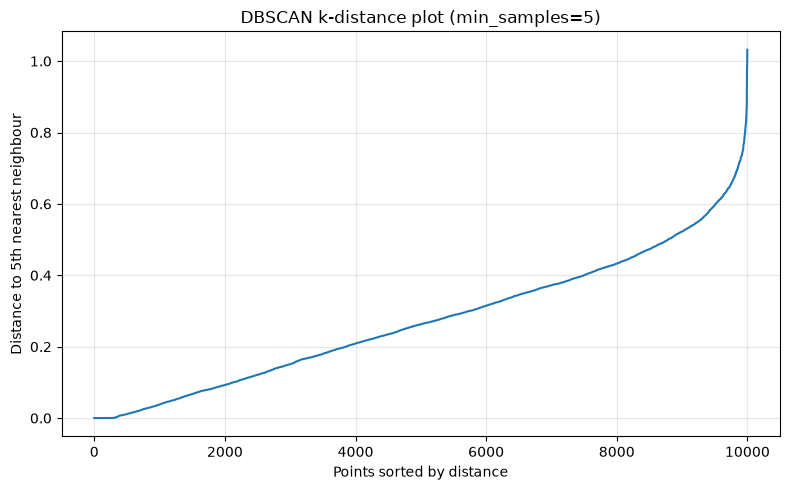

In [14]:
MIN_SAMPLES = 5

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric="euclidean", n_jobs=-1)
nn.fit(X_db_reduced)
distances, _ = nn.kneighbors(X_db_reduced)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.title(f"DBSCAN k-distance plot (min_samples={MIN_SAMPLES})")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 13. Run DBSCAN and inspect its output

Set `DBSCAN_EPS` after reviewing the k-distance plot. The initial value is a starting point only and may need adjustment. A DBSCAN result with one cluster or almost everything marked noise is not automatically a coding error; it can indicate that the current distance representation/parameters do not reveal useful density clusters.

In [15]:
DBSCAN_EPS = 0.25  # Adjust after examining the k-distance plot
DBSCAN_MIN_SAMPLES = 5

dbscan = DBSCAN(
    eps=DBSCAN_EPS,
    min_samples=DBSCAN_MIN_SAMPLES,
    metric="euclidean",
    n_jobs=-1
)

t0 = time.perf_counter()
db_labels = dbscan.fit_predict(X_db_reduced)
dbscan_seconds = time.perf_counter() - t0

work_db["DBSCAN Cluster"] = db_labels
n_noise = int(np.sum(db_labels == -1))
cluster_ids = sorted(set(db_labels) - {-1})

print(f"DBSCAN runtime: {dbscan_seconds:.2f} seconds")
print("Number of clusters (excluding noise):", len(cluster_ids))
print("Noise points:", n_noise, f"({n_noise / len(db_labels):.2%})")
display(work_db["DBSCAN Cluster"].value_counts().sort_index().rename("count").to_frame())

show_cluster_titles(work_db, "DBSCAN Cluster", n_examples=10)


DBSCAN runtime: 0.06 seconds
Number of clusters (excluding noise): 273
Noise points: 4671 (46.71%)


,count
DBSCAN Cluster,
-1,4671
0,105
1,18
2,35
3,33
...,...
268,8
269,8
270,13



Cluster -1 — 4671 products
 • apple iphone 8 plus 14 cm 5.5 64 gb 12 mp ios 11 silver
 • apple mnqq2b/a iphone 7 plus 32gb 5.5 12mp sim free smartphone in rose gold
 • sim free iphone 7 plus 32gb by apple black
 • apple mn8x2b/a iphone 7 32gb 4.7 12mp sim free smartphone in black
 • startech.com usb c to hdmi multi monitor adapter 3 port mst hub usb type c to hdmi monitor splitter usb 3.1 type c black
 • apple iphone iphone x 14.7 cm 5.8 64 gb 12 mp ios 11 silver
 • samsung galaxy s8 sm g950f 14.7 cm 5.8 4 gb 64 gb 4g black 3000 mah
 • samsung galaxy s8 sm g950f 14.7 cm 5.8 64 gb 12 mp android 7
 • 11.938 cm 4.7 1334 x 750 retina hd a10 m10 128gb touch id
 • iphone 7 128gb silver mn932b/a wc01

Cluster 0 — 105 products
 • apple iphone 8 plus 64gb silver
 • sim free iphone 8 plus 64gb by apple space grey
 • iphone 8 plus sim free water dust resistant 64gb silver by apple
 • apple iphone 7 plus 32 gb rose gold
 • apple iphone 7 plus silver 32gb 4g unlocked sim free
 • apple iphone 7 plu

## 14. Compare clusters with existing reference labels (external analysis only)

If `Cluster ID`, `Cluster Label`, or `Category Label` exist, use them only after clustering to understand how the unsupervised assignments align with the supplied reference groupings. This does not make those labels ground truth in every sense, and they were not used to create the TF-IDF vectors.

For DBSCAN, noise is retained as cluster `-1`. The cross-tabulation can be large; display only the most frequent labels.

In [16]:
reference_cols = [c for c in ["Cluster ID", "Cluster Label", "Category Label"] if c in work.columns]

if reference_cols:
    print("K-Means cross-tabs against existing labels:")
    for ref_col in reference_cols:
        print(f"\nK-Means Cluster vs {ref_col}")
        display(pd.crosstab(work["KMeans Cluster"], work[ref_col]).iloc[:, :15])

    if "DBSCAN Cluster" in work_db.columns:
        print("\nDBSCAN cross-tabs against existing labels (DBSCAN sample only):")
        for ref_col in reference_cols:
            print(f"\nDBSCAN Cluster vs {ref_col}")
            display(pd.crosstab(work_db["DBSCAN Cluster"], work_db[ref_col]).iloc[:, :15])
else:
    print("No reference cluster/category columns available for external comparison.")


K-Means cross-tabs against existing labels:

K-Means Cluster vs Cluster ID


Cluster ID,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
KMeans Cluster,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,4,5,2,1,4,5,4,2,2,2,3,4,3,4,4
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,1,1,1,1,1,2,1,1,1,2,1,1,2,1,1
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



K-Means Cluster vs Cluster Label


Cluster Label,AEG A71101TSX0 Stainless Steel,AEG A72020GNW0 White,AEG A72700GNX0 Silver,AEG A72710GNW0 White,AEG A72710GNX0 Silver,AEG A81000TNW0 White,AEG ABB66011AS Integrated,AEG ABB68211AF Integrated,AEG ABB6821VAF Integrated,AEG ABB68811LS Integrated,AEG ABB68821LS Integrated,AEG ABB8121VNF Integrated,AEG ABB81816NC Integrated,AEG ABB81816VNC Integrated,AEG ABB8181VNC Integrated
KMeans Cluster,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,3,5,0,0,0,3,1,1
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1,0,1,0,0,1,0,0,0,0,0,1,0,0,1
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



K-Means Cluster vs Category Label


...

Cluster ID,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
DBSCAN Cluster,,,,,,,,,,,,,,,
-1,1,2,1,1,1,2,0,2,1,0,2,0,1,0,1
0,3,6,5,4,5,0,6,6,4,7,0,2,0,3,3
1,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,2,0,0,0,0,1,0,5,0,0
3,0,0,0,0,0,0,1,1,1,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
269,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
270,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



DBSCAN Cluster vs Cluster Label


Cluster Label,AEG A71101TSX0 Stainless Steel,AEG A72020GNW0 White,AEG A72710GNX0 Silver,AEG ABB68211AF Integrated,AEG ABB6821VAF Integrated,AEG ABB68821LS Integrated,AEG ABB8121VNF Integrated,AEG ABB8181VNC Integrated,AEG ABE6821VNF Integrated,AEG ABE6822VAF Integrated,AEG ABE6882VLS Integrated,AEG ABE8122VNC White,AEG ABE81826NC Integrated,AEG AGB62226NX Stainless Steel,AEG AGB62521NW White
DBSCAN Cluster,,,,,,,,,,,,,,,
-1,1,1,0,1,1,1,1,2,1,2,1,1,1,1,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
269,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
270,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



DBSCAN Cluster vs Category Label


Category Label,CPUs,Digital Cameras,Dishwashers,Freezers,Fridge Freezers,Fridges,Microwaves,Mobile Phones,TVs,Washing Machines
DBSCAN Cluster,,,,,,,,,,
-1,209,326,473,421,924,609,377,461,377,494
0,0,0,0,0,0,0,0,105,0,0
1,0,0,0,0,0,0,0,18,0,0
2,0,0,0,0,0,0,0,35,0,0
3,0,0,0,0,0,0,0,33,0,0
...,...,...,...,...,...,...,...,...,...,...
268,0,0,0,0,0,8,0,0,0,0
269,0,0,0,0,0,8,0,0,0,0
270,0,0,0,0,0,13,0,0,0,0


## 15. Save clustering outputs

The output files include the original data columns and the newly generated assignments. The reference labels are preserved for interpretation but were not included in the clustering inputs.

In [17]:
kmeans_output_path = "product_titles_kmeans_clusters.csv"
work.to_csv(kmeans_output_path, index=False)
print("Saved K-Means output:", os.path.abspath(kmeans_output_path))

if "DBSCAN Cluster" in work_db.columns:
    dbscan_output_path = "product_titles_dbscan_clusters_sample.csv"
    work_db.to_csv(dbscan_output_path, index=False)
    print("Saved DBSCAN output:", os.path.abspath(dbscan_output_path))


Saved K-Means output: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/Machine-Learning/projects/product_titles_kmeans_clusters.csv
Saved DBSCAN output: /Users/ismailhossain/Desktop/SETU_Study/Practical Machine Learning/Machine-Learning/projects/product_titles_dbscan_clusters_sample.csv


## Interpretation checklist

Before finalising a clustering result, review:

- Do products in each K-Means cluster share a recognisable brand/model/product identity?
- Does the elbow curve show a plausible bend, and does the silhouette score support a similar K?
- Does DBSCAN identify meaningful dense groups, or mostly noise?
- Are results sensitive to TF-IDF options (`ngram_range`, `min_df`, `max_df`)?
- Does SVD preserve enough information for DBSCAN to be meaningful?
- How do generated clusters compare with the pre-existing `Cluster ID` and product `Category Label`?
- Are we comparing like with like? Existing cluster labels may be fine-grained product-identity groups, while category labels may be broader.

Do not choose the final method solely from one score. Combine metrics with manual inspection of representative product titles.
